<a href="https://colab.research.google.com/github/Uma-arul/World-energy-consumption/blob/main/World_Energy_Consumption.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Loading the uploaded dataset
df = pd.read_csv('World_Energy_By_Country_And_Region_1965_to_2023.csv')

# Displaying dataset structure
print("Dataset Columns:\n", df.columns.tolist())
print("\nFirst 5 Rows:")
print(df.head())

Dataset Columns:
 ['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']

First 5 Rows:
               Country   1965   1966   1967   1968   1969   1970   1971  \
0                  NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
1               Canada   5.00   5.32   5.57   5.92   6.28   6.73   6.94   
2               Mexico   1.06   1.12   1.14   1.24   1.36   1.45   1.53   
3                   US  51.98  54.89  56.80  60.19  63.30  65.54  66.92   
4  Total North America  58.04  61.33  63.51  67.36  70.95  73.72  75.39   

    1972   1973  ...    2014    

In [4]:
import pandas as pd
import numpy as np

# 1. Clean and melt the dataframe into long format
# Remove any completely empty rows and strip whitespace from column names
df_cleaned = df.dropna(how='all').copy()
df_cleaned.columns = df_cleaned.columns.astype(str).str.strip()

# Filter out row-level NaNs in crucial columns
df_cleaned = df_cleaned.dropna(subset=['Country'])

# Get year columns (4-digit numeric column names)
year_cols = [col for col in df_cleaned.columns if col.isdigit() and len(col) == 4]

# Melt from wide to long format
df_long = df_cleaned.melt(
    id_vars=['Country'],
    value_vars=year_cols,
    var_name='Year',
    value_name='Consumption'
)

# Convert types and drop missing values
df_long['Year'] = pd.to_numeric(df_long['Year'])
df_long['Consumption'] = pd.to_numeric(df_long['Consumption'], errors='coerce')
df_long = df_long.dropna(subset=['Consumption'])

# Sort chronologically by Country and Year
df_long = df_long.sort_values(by=['Country', 'Year']).reset_index(drop=True)

display(df_long.head())
print(f"Total long-format records: {len(df_long)}")

,Country,Year,Consumption
0,European Union #,1965,34.03
1,European Union #,1966,35.19
2,European Union #,1967,36.41
3,European Union #,1968,38.98
4,European Union #,1969,42.20


Total long-format records: 5728


In [5]:
# 2. Create sequences using the previous 5 years to predict the 6th year's consumption
# We will group by Country to ensure sequences do not cross between different countries

window_size = 5
X = []
y = []

for country, group in df_long.groupby('Country'):
    # Ensure chronological order within group
    group_sorted = group.sort_values('Year')
    values = group_sorted['Consumption'].values

    if len(values) > window_size:
        for i in range(len(values) - window_size):
            X.append(values[i : i + window_size])
            y.append(values[i + window_size])

X = np.array(X)
y = np.array(y)

print(f"Created {len(X)} sequences.")
print("Shape of X (features):", X.shape)
print("Shape of y (target):", y.shape)
print("\nFirst sample input sequence (X[0]):", X[0])
print("Corresponding target (y[0]):", y[0])

Created 5213 sequences.
Shape of X (features): (5213, 5)
Shape of y (target): (5213,)

First sample input sequence (X[0]): [34.03 35.19 36.41 38.98 42.2 ]
Corresponding target (y[0]): 45.28


In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

# Reshape X to fit the expected 3D input shape for RNNs: [samples, timesteps, features]
# Here, timesteps = 5 (window_size) and features = 1
X_reshaped = X.reshape((X.shape[0], X.shape[1], 1))

# Define the Simple RNN model
model = Sequential([
    SimpleRNN(32, activation='relu', input_shape=(window_size, 1)),
    Dense(16, activation='relu'),
    Dense(1) # Linear activation for regression prediction
])

# Compile the model
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Print model summary
model.summary()

print("\nModel successfully created and compiled!")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,633 (6.38 KB)

 Trainable params: 1,633 (6.38 KB)

 Non-trainable params: 0 (0.00 B)


Model successfully created and compiled!


In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import tensorflow as tf

# 1. Chronological Split (80% Train, 20% Test)
split_index = int(len(X_reshaped) * 0.8)

X_train, X_test = X_reshaped[:split_index], X_reshaped[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

print(f"Training set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")

# 2. Define Custom Callback for regression-based accuracy percentage
class EpochAccuracyCallback(tf.keras.callbacks.Callback):
    def __init__(self, validation_data):
        super().__init__()
        self.x_val, self.y_val = validation_data
    def on_epoch_end(self, epoch, logs=None):
        # Predict validation set
        val_pred = self.model.predict(self.x_val, verbose=0).flatten()
        # Calculate Mean Absolute Percentage Error (MAPE)
        mape = np.mean(np.abs((self.y_val - val_pred) / np.maximum(self.y_val, 1e-5))) * 100
        # Accuracy defined as 100 - MAPE
        accuracy = max(0.0, 100.0 - mape)
        print(f" - Epoch {epoch + 1}: Val Loss = {logs.get('val_loss'):.4f}, Estimated Val Accuracy = {accuracy:.2f}%")

# 3. Train the Model with custom callback
# We will use a subset of training data as explicit validation data for the callback
val_split = int(len(X_train) * 0.9)
X_tr, X_val = X_train[:val_split], X_train[val_split:]
y_tr, y_val = y_train[:val_split], y_train[val_split:]

print("\nStarting Training...")
history = model.fit(
    X_tr, y_tr,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=0,  # Turn off standard verbose to print custom epoch metrics cleaner
    callbacks=[EpochAccuracyCallback((X_val, y_val))]
)

# 4. Evaluate the Model on final Test Set
y_pred = model.predict(X_test).flatten()

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"\n--- Evaluation Results on Test Set ---")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

Training set size: 4170 samples
Testing set size: 1043 samples

Starting Training...
 - Epoch 1: Val Loss = 0.1478, Estimated Val Accuracy = 91.09%
 - Epoch 2: Val Loss = 0.0285, Estimated Val Accuracy = 95.11%
 - Epoch 3: Val Loss = 0.0314, Estimated Val Accuracy = 93.66%
 - Epoch 4: Val Loss = 0.1124, Estimated Val Accuracy = 87.49%
 - Epoch 5: Val Loss = 0.0484, Estimated Val Accuracy = 88.91%
 - Epoch 6: Val Loss = 0.0452, Estimated Val Accuracy = 94.20%
 - Epoch 7: Val Loss = 0.0364, Estimated Val Accuracy = 94.98%
 - Epoch 8: Val Loss = 0.0355, Estimated Val Accuracy = 94.77%
 - Epoch 9: Val Loss = 0.0374, Estimated Val Accuracy = 94.37%
 - Epoch 10: Val Loss = 0.0315, Estimated Val Accuracy = 94.06%
 - Epoch 11: Val Loss = 0.0457, Estimated Val Accuracy = 94.70%
 - Epoch 12: Val Loss = 0.0451, Estimated Val Accuracy = 93.69%
 - Epoch 13: Val Loss = 0.0287, Estimated Val Accuracy = 94.98%
 - Epoch 14: Val Loss = 0.0277, Estimated Val Accuracy = 95.08%
 - Epoch 15: Val Loss = 0.02

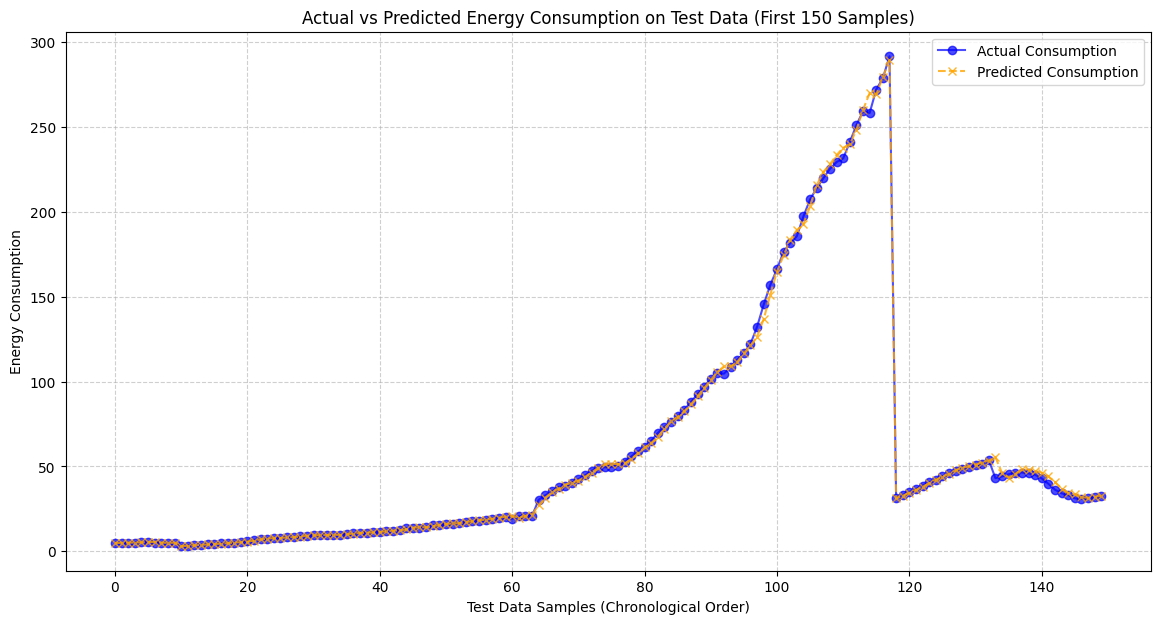

In [9]:
import matplotlib.pyplot as plt

# Plotting actual versus predicted energy consumption for a portion of the test data
plt.figure(figsize=(14, 7))

# We will plot the first 150 test samples to keep the plot highly readable
samples_to_plot = 150
plt.plot(y_test[:samples_to_plot], label='Actual Consumption', color='blue', alpha=0.7, marker='o')
plt.plot(y_pred[:samples_to_plot], label='Predicted Consumption', color='orange', alpha=0.8, linestyle='--', marker='x')

plt.title('Actual vs Predicted Energy Consumption on Test Data (First 150 Samples)')
plt.xlabel('Test Data Samples (Chronological Order)')
plt.ylabel('Energy Consumption')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()